# Center-notch construction in Ti₂N Mxene monolayer for fracture study

Pre-cracked sheets for the fracture simulations are generated from pristine LAMMPS data files by removing a central row or column of atoms. Quantized fracture mechanics (QFM) treats crack advance as discrete steps, each corresponding to the removal of a fixed set of atoms, so the notch geometry has to be known exactly. The selection algorithm was therefore built from the lattice geometry and atomic coordinates, and the nominal crack length is expressed as a function of the number of removed atoms and the lattice spacing.


## 1. Notch families

Notches are cut about the geometric centre of the sheet and fall into two families.

| Family | Removed atoms | Crack direction | Tip termination |
|:--|:--|:--|:--|
| Armchair (AC) | single centre column | along $y$ | Ti-tip or N-tip, set by notch length |
| Zigzag (ZZ) | three-row band on the notch line | along $x$ | V-tip or flat-tip |

In the armchair case the slit ends on a single lattice site, so the tip chemistry alternates with notch length. The wider zigzag band leaves two recurring terminal shapes, a pointed V-tip and a flat-tip. Notch width follows from this construction rule and is not varied independently of the family.

**Construction schematics.** Left: armchair, right: zigzag. Removed titanium and nitrogen atoms are shown, The atomic model shown below was made analyzing the data files in OVITO 

![construction schematics](media/schematics-768a6b82.png)
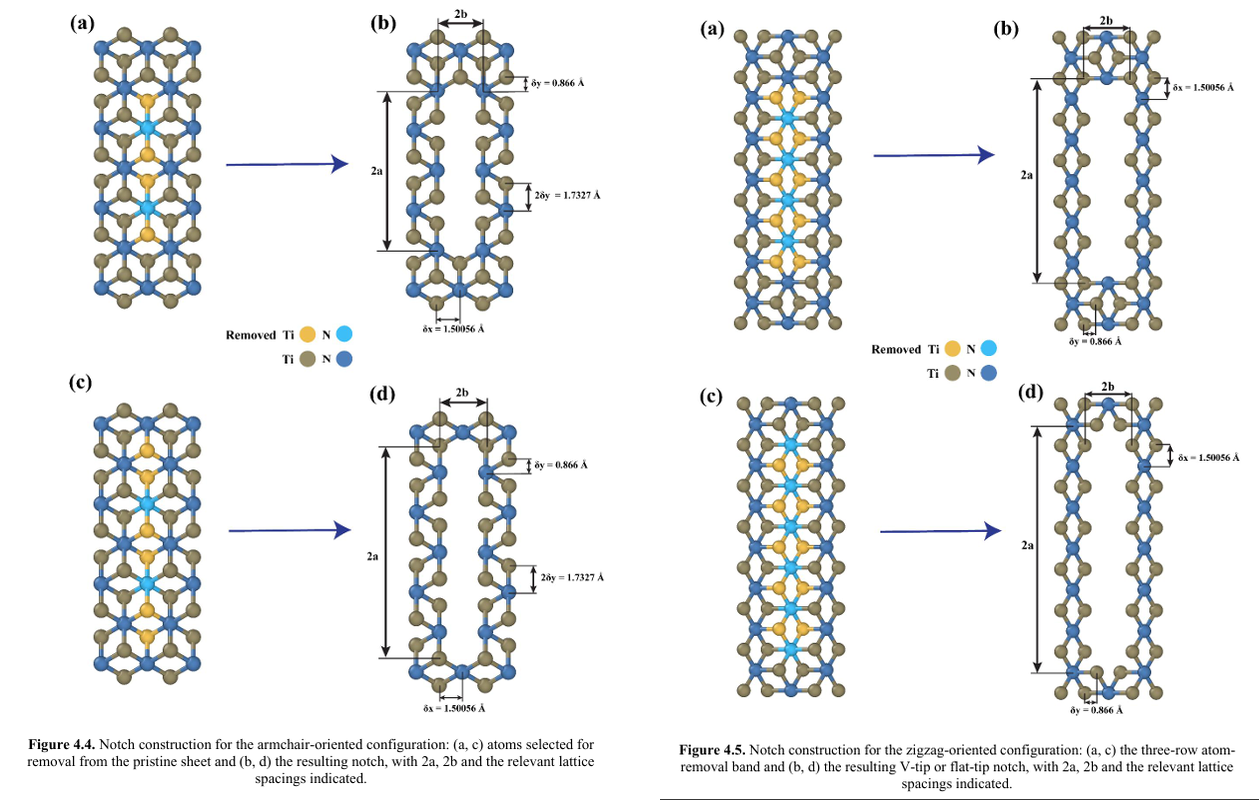

## 2. Nominal crack length

The full crack length $2a$ is assigned from the lattice geometry and the numbers of removed titanium ($N_{Ti}$) and nitrogen ($N_N$) atoms. 

For the zigzag notch, with lattice spacing $\delta_x = 1.500555$ Å along the notch line,

$$2a_{ZZ} = \frac{1}{2}\,\delta_x\,\left(N_{Ti} + 2N_{N} + 2\right) \tag{1}$$

and for the single-column armchair notch, with $\delta_y = 0.866347$ Å,

$$2a_{AC} = 2\,\delta_y\,\left(N_{Ti} + N_{N}\right) \tag{2}$$

For example, the $n = 7$ ZZ notch removes 14 Ti and 8 N atoms, giving $2a = \tfrac{1}{2}(1.500555)(14 + 16 + 2) = 24.0089$ Å, and the $n = 6$ AC notch removes 8 Ti and 4 N atoms, giving $2a = 2(0.866347)(8 + 4) = 20.7923$ Å. Both values are reproduced from the selected atoms in Section 4.

## 3. Atom selection

1. The pristine sheet is read as `type, x, y` and the grid spacings $\delta_x$, $\delta_y$ are taken from the coordinates.
2. Atoms are indexed on an integer grid $(g_x, g_y)$ about the sheet centre.
3. A notch of size $n$ is the set of atoms with $|g_\parallel| \le g_n$ along the crack and $|g_\perp| \le w$ across it, with $w = 1$ for zigzag and $w = 0$ for armchair. Only odd $g_y$ carry atoms in the central armchair column, so armchair notch $n$ maps to $g_n = 2n - 1$.
4. The removed species are counted and $2a$ follows from Eq. (1) or (2); the tip type is read from the end of the slit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DX, DY = 1.500555, 0.866347          # grid spacings along x and y, Å


def pristine_patch(half=45):
    gx, gy = np.meshgrid(np.arange(-half, half + 1), np.arange(-half, half + 1))
    gx, gy = gx.ravel(), gy.ravel()
    occupied = (gx + gy) % 2 == 1                        # atoms sit on alternate grid points
    gx, gy = gx[occupied], gy[occupied]
    stack = ((gy - 1 - 3 * gx) // 2) % 3                 # Ti-N-Ti stacking seen in projection
    return pd.DataFrame({"type": np.where(stack == 1, 1, 2), "x": gx * DX, "y": gy * DY})


atoms = pristine_patch()
print(f"{len(atoms)} atoms in patch:", atoms.type.map({1: "N", 2: "Ti"}).value_counts().to_dict())

4140 atoms in patch: {'Ti': 2730, 'N': 1410}


In [2]:
def make_notch(atoms, family, n):
    zz = family == "zigzag"
    along, across = ("gx", "gy") if zz else ("gy", "gx")
    g_n, g_w = (n, 1) if zz else (2 * n - 1, 0)

    sheet = atoms.assign(gx=np.round(atoms.x / DX).astype(int),
                         gy=np.round(atoms.y / DY).astype(int))
    cut = (sheet[along].abs() <= g_n) & (sheet[across].abs() <= g_w)
    removed, remaining = sheet[cut], sheet[~cut]

    n_ti, n_n = int((removed.type == 2).sum()), int((removed.type == 1).sum())
    if zz:
        length = 0.5 * DX * (n_ti + 2 * n_n + 2)                       # Eq. (1)
        tip = "V-tip" if (removed.gx == g_n).sum() == 1 else "flat-tip"
    else:
        length = 2 * DY * (n_ti + n_n)                                 # Eq. (2)
        first = remaining[(remaining.gx == 0) & (remaining.gy == g_n + 2)]
        tip = "N-tip" if first.type.iloc[0] == 1 else "Ti-tip"
    return removed, remaining, dict(n=n, n_ti=n_ti, n_n=n_n, length=length, tip=tip)

## 4. Worked examples

Applying the selection to the two notches quoted above and evaluating Eqs. (1) and (2) from the removed counts:

In [3]:
rows = []
for family, n in [("zigzag", 7), ("armchair", 6)]:
    _, _, r = make_notch(atoms, family, n)
    rows.append({"Orientation": family.capitalize(), "n": n, "Removed Ti": r["n_ti"],
                 "Removed N": r["n_n"], "Tip": r["tip"], "2a (Å)": r["length"]})
    if family == "zigzag":
        print(f"ZZ n={n}:  2a = 1/2 x {DX} x ({r['n_ti']} + 2 x {r['n_n']} + 2) = {r['length']:.4f} Å")
    else:
        print(f"AC n={n}:  2a = 2 x {DY} x ({r['n_ti']} + {r['n_n']}) = {r['length']:.4f} Å")

display(pd.DataFrame(rows).style.hide(axis="index").format({"2a (Å)": "{:.4f}"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

ZZ n=7:  2a = 1/2 x 1.500555 x (14 + 2 x 8 + 2) = 24.0089 Å
AC n=6:  2a = 2 x 0.866347 x (8 + 4) = 20.7923 Å


Orientation,n,Removed Ti,Removed N,Tip,2a (Å)
Zigzag,7,14,8,V-tip,24.0089
Armchair,6,8,4,Ti-tip,20.7923


## 5. Resulting notch geometries

In [4]:
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.colors import to_rgb
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from scipy.spatial import cKDTree

COLOR = {"Ti": "#8c7e5c", "N": "#3f6fb3", "Ti_cut": "#f2b134", "N_cut": "#34b4e8"}
RADIUS = {1: 0.60, 2: 0.52}


def shade(color, f):
    return tuple(np.clip(np.array(to_rgb(color)) * f, 0, 1))


def draw_sheet(ax, sheet, cut=(), win=(8, 6), lim=(9, 7)):
    w = sheet[(sheet.x.abs() < win[0]) & (sheet.y.abs() < win[1])]
    xy, kind, hot = w[["x", "y"]].to_numpy(), w.type.to_numpy(), w.index.isin(cut)

    pairs = np.array(sorted(cKDTree(xy).query_pairs(1.05 * 2 * DY)))
    pairs = pairs[(kind[pairs[:, 0]] == 1) | (kind[pairs[:, 1]] == 1)]          # Ti-N bonds only
    ax.add_collection(LineCollection(xy[pairs], colors="#9aa6b2", linewidths=2.6, zorder=1, capstyle="round"))

    for name, t, h in [("Ti", 2, False), ("N", 1, False), ("Ti_cut", 2, True), ("N_cut", 1, True)]:
        pts, r = xy[(kind == t) & (hot == h)], RADIUS[t]
        ax.add_collection(PatchCollection([Circle(p, r) for p in pts], facecolor=COLOR[name],
                                          edgecolor=shade(COLOR[name], 0.62), linewidths=0.9, zorder=3))
        ax.add_collection(PatchCollection([Circle(p + (-0.28 * r, 0.30 * r), 0.36 * r) for p in pts],
                                          facecolor="white", alpha=0.32, linewidths=0, zorder=4))
    ax.set(xlim=(-lim[0], lim[0]), ylim=(-lim[1], lim[1]), aspect="equal")
    ax.axis("off")


def dimension(ax, a, pos, text, horizontal):
    arrow = dict(arrowstyle="<|-|>", color="k", lw=1.3, mutation_scale=11, shrinkA=0, shrinkB=0)
    for s in (-1, 1):
        if horizontal:
            ax.plot([s * a, s * a], [-1.3, pos + 0.5], color="k", lw=0.9, zorder=5)
        else:
            ax.plot([-1.3, pos + 0.5], [s * a, s * a], color="k", lw=0.9, zorder=5)
    if horizontal:
        ax.annotate("", xy=(-a, pos), xytext=(a, pos), arrowprops=arrow, zorder=6)
        ax.text(0, pos + 0.55, text, ha="center", va="bottom", fontsize=11, fontweight="bold")
    else:
        ax.annotate("", xy=(pos, -a), xytext=(pos, a), arrowprops=arrow, zorder=6)
        ax.text(pos + 0.55, 0, text, ha="left", va="center", rotation=90, fontsize=11, fontweight="bold")


def notch_figure(family, sizes):
    zz = family == "zigzag"
    runs = [make_notch(atoms, family, n) for n in sizes]
    a_max = max(r[2]["length"] for r in runs) / 2
    win, lim = ((a_max + 4.5, 4.6), (a_max + 5, 7.4)) if zz else ((4.7, a_max + 4.5), (7.4, a_max + 5))

    if zz:
        fig = plt.figure(figsize=(12, 2.9 * len(runs) + 0.6))
        gs = GridSpec(len(runs), 3, width_ratios=[1, 0.16, 1], hspace=0.04, wspace=0.02,
                      left=0.02, right=0.98, top=0.99, bottom=0.09)
        slots = [(gs[i, 0], gs[i, 1], gs[i, 2]) for i in range(len(runs))]
    else:
        fig = plt.figure(figsize=(12, 6.4))
        gs = GridSpec(1, 7, width_ratios=[1, 0.3, 1, 0.5, 1, 0.3, 1], wspace=0,
                      left=0.02, right=0.98, top=0.99, bottom=0.09)
        slots = [(gs[0, 0], gs[0, 1], gs[0, 2]), (gs[0, 4], gs[0, 5], gs[0, 6])]

    for k, ((removed, remaining, info), slot) in enumerate(zip(runs, slots)):
        before, mid, after = (fig.add_subplot(s) for s in slot)
        draw_sheet(before, atoms, cut=removed.index, win=win, lim=lim)
        draw_sheet(after, remaining, win=win, lim=lim)
        dimension(after, info["length"] / 2, 5.6, f"2a = {info['length']:.2f} Å   ({info['tip']})", zz)
        mid.axis("off")
        mid.annotate("", xy=(1, 0.5), xytext=(0, 0.5), xycoords="axes fraction",
                     arrowprops=dict(arrowstyle="-|>", color="#2a2c8c", lw=2.4, mutation_scale=20))
        for ax, letter in zip((before, after), "abcd"[2 * k:2 * k + 2]):
            ax.text(0, 1, f"({letter})", transform=ax.transAxes, fontsize=15, fontweight="bold", va="top")

    keys = [("Removed Ti", "Ti_cut"), ("Removed N", "N_cut"), ("Ti", "Ti"), ("N", "N")]
    fig.legend([Line2D([], [], marker="o", ls="", markersize=12, markerfacecolor=COLOR[c],
                       markeredgecolor=shade(COLOR[c], 0.62), label=l) for l, c in keys],
               [l for l, _ in keys], loc="lower center", ncol=4, frameon=False, fontsize=11,
               bbox_to_anchor=(0.5, 0.0), handletextpad=0.3, columnspacing=1.8)
    fig.savefig(f"notch_{family}.png", dpi=200, bbox_inches="tight")
    plt.show()

**Zigzag notches, $n = 6$ (flat-tip) and $n = 7$ (V-tip).** The three-row band is removed along the notch line; the slit ends either on a pair of atoms (flat-tip) or on a single atom (V-tip).

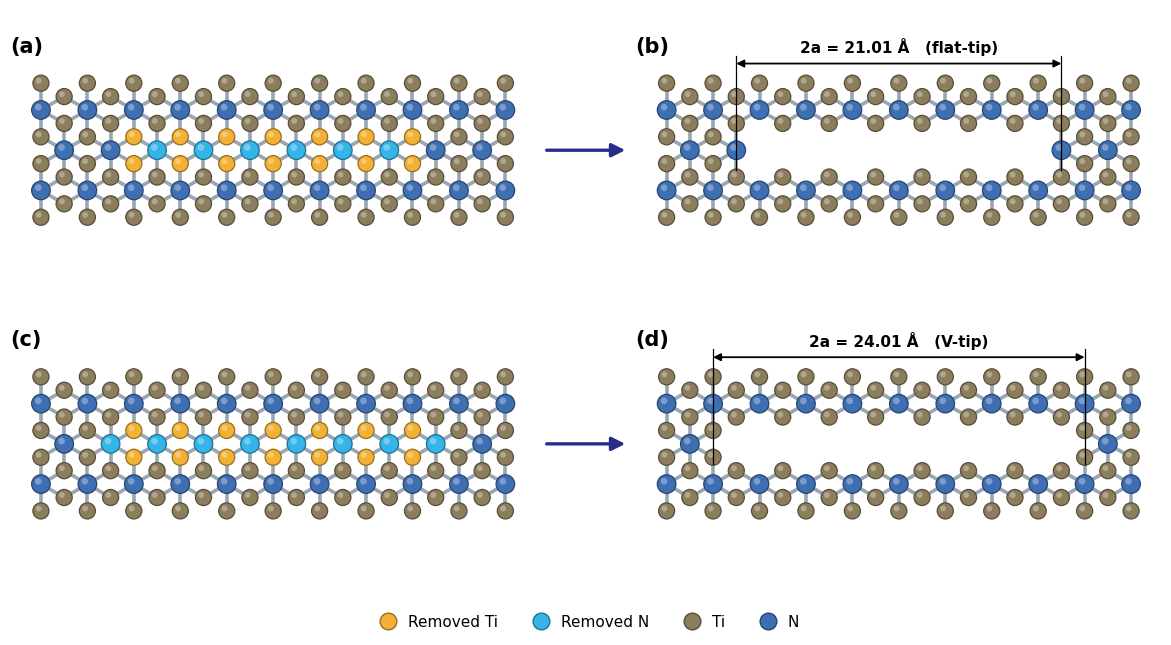

In [5]:
notch_figure("zigzag", sizes=(6, 7))

**Armchair notches, $n = 6$ (Ti-tip) and $n = 7$ (N-tip).** The single central column is removed, so the slit ends on one lattice site and the tip species alternates with notch length.

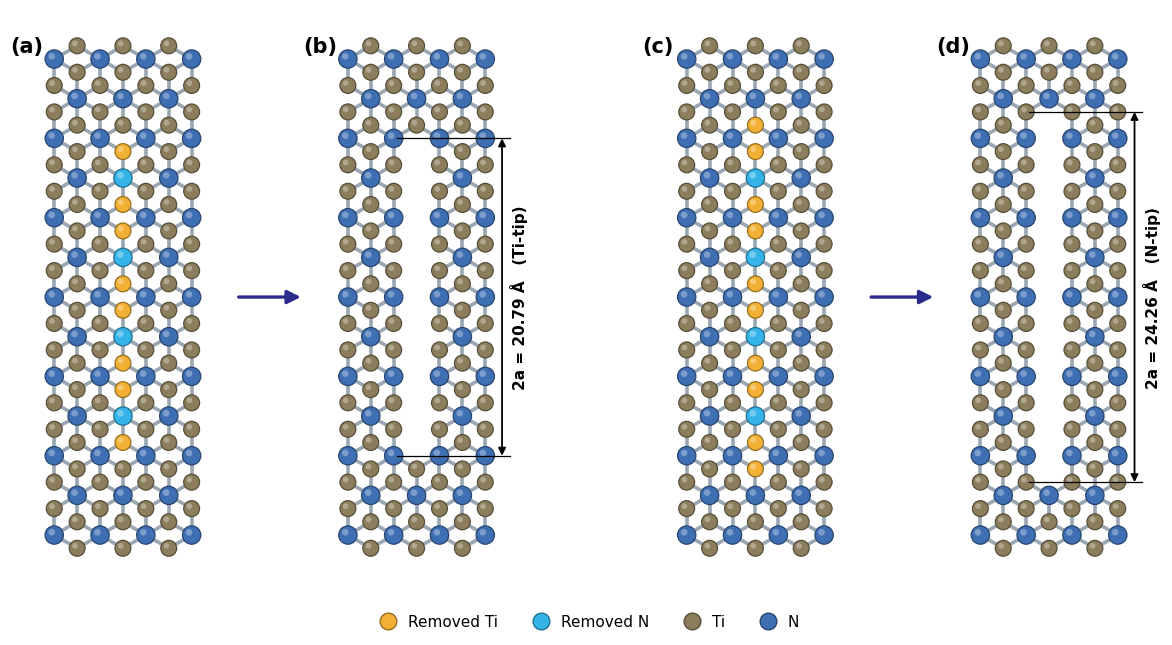

In [6]:
notch_figure("armchair", sizes=(6, 7))